# 01 · Data pipeline and quality check

**Run this first.** It turns the raw Avangrid files into clean tables everyone else works from, then shows what was found and fixed in the data.

| Step | What happens | Output |
|---|---|---|
| 1. Read AMI | Streams every `part-*.csv` in each delivery zip/folder into a customer × 8,760-hour matrix | `data/processed/kwh_raw.npy` |
| 2. Weather | Aligns hourly weather to the same 8,760 hours, fills the March gap | `outputs/weather_*.csv` |
| 3. Clean | Masks zero-glitch hours and catch-up spikes, fills gaps, flags low-quality customers | `data/processed/kwh_clean.npy` |
| 4. System load | Sums all loaded customers per hour, ranks the peak hours | `outputs/system_load_hourly.csv` |
| 5. Features | ~100 descriptive features per customer + reference labels + quality flags | `outputs/customer_features.parquet` / `.csv` |
| 6. Profiles | Seasonal hourly profiles and daily kWh per customer | `outputs/seasonal_profiles.parquet`, `daily_kwh.parquet` |

Everything here is *mechanical*: no appliance rules, segments or battery candidates. Those live in notebooks `10`, `20` and `30`.

**Data location.** Put the four AMI zips (or their unzipped folders), the weather workbook and the EV/HP/PV workbook in `data/raw/`. Names like `2026_Avangrid_Hackathon_Data_1_10000.zip` or `2026 Avangrid Hackathon Data_1_10000` are both recognised. The first run reads each zip once (about 2 minutes per 10,000 customers on a laptop) and caches it, so later runs take seconds.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from avangrid.config import Paths, PROGRAM_BATTERY, INCREMENTAL_LOAD_LIMIT_KVA, SERVICE_KVA
from avangrid import pipeline, plots, labels, battery, features
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 200)
P = Paths(ROOT)
P.ensure()
from avangrid.io_ami import find_ami_sources, diagnose_raw_dir
print("Raw folder:", P.raw)
for s in find_ami_sources(P.raw):
    print(f"  AMI delivery {s.tag:>12}  ({s.kind})  {s.path.name}")
for w in diagnose_raw_dir(P.raw):
    print("  WARNING:", w)   # fix these before running the pipeline

Raw folder: /Users/hoodi/Downloads/avangrid-hackathon/data/raw
  AMI delivery      1_10000  (dir)  2026 Avangrid Hackathon Data_1_10000
  AMI delivery  20001_30000  (dir)  2026 Avangrid Hackathon Data_20001_30000
  AMI delivery  30001_35725  (dir)  2026 Avangrid Hackathon Data_30001_35725


## Run the pipeline
Set `rebuild=True` only if the raw files changed. Adding the other three zips later is fine: only the new ones are read.

In [2]:
summary = pipeline.run(P, rebuild=False)
D = pipeline.load_project(P)
print(f"{len(D.customers):,} customers loaded; feature table {D.table.shape}")

1/6  Reading AMI deliveries ...
!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
Delivery 1_10000 (dir): 2026 Avangrid Hackathon Data_1_10000
Delivery 20001_30000 (dir): 2026 Avangrid Hackathon Data_20001_30000
Delivery 30001_35725 (dir): 2026 Avangrid Hackathon Data_30001_35725
     25,653 customers x 8,760 hours from deliveries 1_10000, 20001_30000, 30001_35725
2/6  Weather ...
3/6  Cleaning + gap filling ...
  cleaned 25,653/25,653
4/6  System load ...
5/6  Features ...
  features 25,653/25,653
6/6  Profile tables ...
Done in 0.9 min. Outputs in /Users/hoodi/Downloads/avangrid-hackathon/outputs
25,653 customers loaded; feature table (25653, 106)


## 1 · What the raw AMI data looks like

In [3]:
import json
stats = pd.DataFrame({p.stem.replace("_stats", "").replace("ami_", ""): json.loads(p.read_text())
                      for p in sorted(P.processed.glob("ami_*_stats.json"))}).T
stats["customers_missing_n"] = stats["customers_missing"].apply(len)
stats[["parts", "rows", "customers_expected", "customers_present", "customers_missing_n", "customers_in_multiple_parts",
       "rows_incomplete", "rows_negative", "duplicate_hours", "interval_types"]]

,parts,rows,customers_expected,customers_present,customers_missing_n,customers_in_multiple_parts,rows_incomplete,rows_negative,duplicate_hours,interval_types
1_10000,52,87044582,10000,9984,16,51,0,0,0,"[15-min, 5-min]"
20001_30000,51,86678965,10000,9965,35,50,0,0,0,[15-min]
30001_35725,52,49595616,5725,5704,21,51,0,0,0,[15-min]


**Findings (30001-35725 delivery; re-check once all four are loaded):**
* Every row is a complete hour (`INTERVAL_COUNT = 4`, `IS_COMPLETE_HOUR = 1`). Missing data shows up as **missing rows**, not flagged rows.
* **No negative values.** The channel is grid *imports* only, so solar customers show **zeros** at midday, not exports. Export volumes can't be measured from this data.
* Each DST day is missing one hour (11/2/2025 HE2, 3/8/2026 HE3). The wall-clock grid keeps 24 slots per day and fills them.
* `USAGE_DATE` is ISO (`2025-09-01`) in the files, not `MM/DD/YYYY` as in the dictionary. Both are handled.
* A customer's rows can be spread over several `part-*.csv` files.

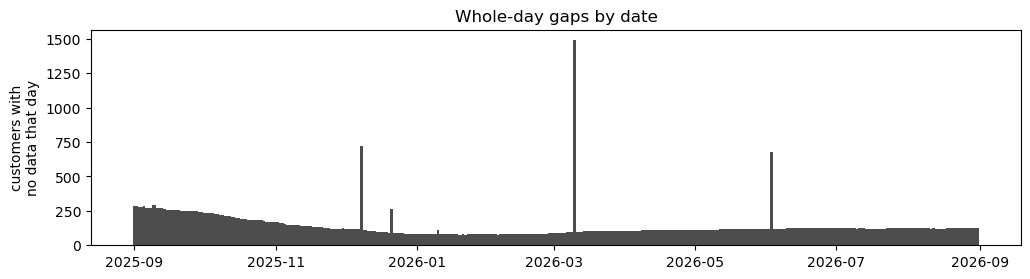

Dates where >1% of customers have no data:
2026-03-10    1492
2025-12-08     725
2026-06-03     679
2025-09-09     295
2025-09-10     292
2025-09-01     284
2025-09-05     284
2025-09-02     283
2025-09-03     280
2025-09-04     279
dtype: int64

Customer numbers with no data at all: [863, 1528, 3925, 4699, 4700, 5070, 5348, 6467, 6494, 6817, 6963, 7370, 7374, 7716, 7719, 8590, 20057, 20128, 20366, 20773, 21251, 21768, 22056, 22274, 22862, 23237, 23598, 23897, 24302, 24913, 24919, 25175, 26285, 26535, 27073, 27082, 27178, 27325, 28011, 28529, 28557, 28726, 28839, 28847, 28848, 29149, 29210, 29750, 29802, 29900, 29958, 30334, 30340, 30589, 30676, 30694, 31717, 32413, 32443, 32635, 32636, 32671, 32792, 33220, 33398, 33427, 33508, 33882, 34012, 35102, 35121, 35232]


In [4]:
raw = D.kwh_raw
day_missing = np.zeros(365, int)
for i in range(0, len(raw), 4000):
    x = np.asarray(raw[i:i+4000])
    day_missing += np.isnan(x).reshape(len(x), 365, 24).all(2).sum(0)
dates = pd.date_range("2025-09-01", periods=365)
fig, ax = plt.subplots(figsize=(12, 2.8))
ax.bar(dates, day_missing, width=1.0, color="0.3")
ax.set_ylabel("customers with\nno data that day"); ax.set_title("Whole-day gaps by date")
plt.show()
print("Dates where >1% of customers have no data:")
print(pd.Series(day_missing, index=dates.date)[day_missing > 0.01 * len(raw)].sort_values(ascending=False).head(10))
print("\nCustomer numbers with no data at all:", summary["missing_customer_numbers"])

## 2 · Cleaning
**Zero-glitch hours.** Normally ~1-2% of meters read exactly 0 in any hour (vacant homes, solar at midday). An hour is flagged when the share reading 0 is both **2× and 1 percentage point above** the usual share for that hour of day, which points to an outage or data glitch hitting hundreds of meters at once. Those zeros are treated as missing **only for customers who rarely read 0**, so solar and vacant homes keep their genuine zeros. Keep the table: `excess_meters_est` is roughly how many meters were affected, a possible reliability insight.

In [5]:
pd.read_csv(P.outputs / "anomalous_zero_hours.csv")

,slot,ts,meters_reading_zero,share_reading_zero,typical_share_this_hour,excess_meters_est
0,1137,2025-10-18 09:00:00,636,0.0250,0.0105,368
1,1138,2025-10-18 10:00:00,948,0.0372,0.0124,632
2,1367,2025-10-27 23:00:00,1805,0.0709,0.0078,1607
3,1581,2025-11-05 21:00:00,589,0.0231,0.0077,394
4,2741,2025-12-24 05:00:00,1186,0.0464,0.0079,985
5,3156,2026-01-10 12:00:00,1922,0.0752,0.0134,1580
6,3157,2026-01-10 13:00:00,1912,0.0749,0.0130,1581
7,3158,2026-01-10 14:00:00,648,0.0254,0.0127,325
8,5512,2026-04-18 16:00:00,778,0.0305,0.0104,513
9,5513,2026-04-18 17:00:00,710,0.0278,0.0086,490


In [6]:
T = D.table
qcols = ["flag_partial_year", "flag_low_coverage", "flag_mostly_zero", "analysis_ready"]
display(T[qcols].sum().rename("customers").to_frame())
display(T[["coverage", "filled_share", "hours_zero_glitch_masked", "hours_spike_masked", "whole_days_missing", "longest_gap_h"]]
        .describe(percentiles=[.5, .9, .99]).T.round(3))

,customers
flag_partial_year,365
flag_low_coverage,360
flag_mostly_zero,140
analysis_ready,25170


,count,mean,std,min,50%,90%,99%,max
coverage,25653.0,0.994,0.049,0.01,1.0,1.000,1.000,1.00
filled_share,25653.0,0.006,0.049,0.00,0.0,0.006,0.182,0.99
hours_zero_glitch_masked,25653.0,0.609,1.165,0.00,0.0,2.000,6.000,13.00
hours_spike_masked,25653.0,0.000,0.038,0.00,0.0,0.000,0.000,6.00
whole_days_missing,25653.0,1.960,17.714,0.00,0.0,1.000,66.000,361.00
longest_gap_h,25653.0,50.965,424.907,1.00,1.0,24.000,1595.000,8676.00


Before vs after for one customer with a missing day (grey = raw, orange = filled):

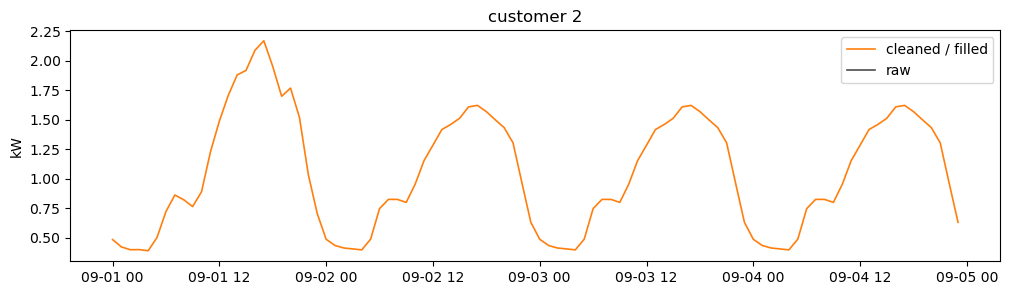

In [7]:
ex = T[(T.whole_days_missing > 0) & T.analysis_ready].customer_number.iloc[0]
raw_s, cln = D.series(ex, raw=True), D.series(ex)
d0 = int(np.where(np.isnan(raw_s.reshape(365, 24)).all(1))[0][0])
sl = slice(max(d0 - 3, 0) * 24, min(d0 + 4, 365) * 24)
fig, ax = plt.subplots(figsize=(12, 3))
ts = D.hours.ts.iloc[sl]
ax.plot(ts, cln[sl], color="tab:orange", lw=1.2, label="cleaned / filled")
ax.plot(ts, raw_s[sl], color="0.3", lw=1.2, label="raw")
ax.set_ylabel("kW"); ax.set_title(f"customer {ex}"); ax.legend(); plt.show()

## 3 · Weather
TIME `0:00` is matched to AMI hour-ending 1. The duplicated 1 AM reading on 11/2/2025 is averaged. The 94-hour gap on 3/8-3/11/2026 is filled with the daily-mean trend plus the average hour-of-day shape (shaded red below).

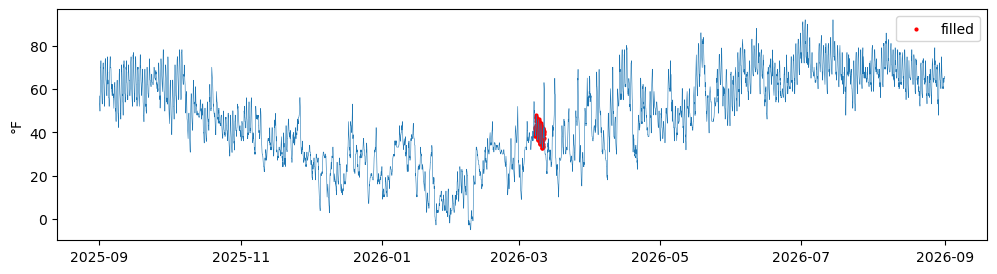

Heating degree days (65°F): 7,112   Cooling degree days: 383
Coldest day 2026-02-08 (-1.1°F mean); hottest 2026-07-02 (81.8°F)


In [8]:
w = D.weather
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(w.ts, w.temp_f, lw=0.4, color="tab:blue")
f = w[w.temp_f_filled]; ax.scatter(f.ts, f.temp_f, s=4, color="red", label="filled")
ax.set_ylabel("°F"); ax.legend(); plt.show()
wd = D.weather_daily
print(f"Heating degree days (65°F): {wd.hdd65.sum():,.0f}   Cooling degree days: {wd.cdd65.sum():,.0f}")
print(f"Coldest day {wd.loc[wd.temp_mean.idxmin(), 'date'].date()} ({wd.temp_mean.min():.1f}°F mean); "
      f"hottest {wd.loc[wd.temp_mean.idxmax(), 'date'].date()} ({wd.temp_mean.max():.1f}°F)")

## 4 · System load
`system_kw` is the sum of every customer **loaded in this run**, so it reflects only the deliveries present in `data/raw`. Rank 1 = highest hour. `rank_winter` / `rank_summer` rank within Dec-Feb and Jun-Aug.

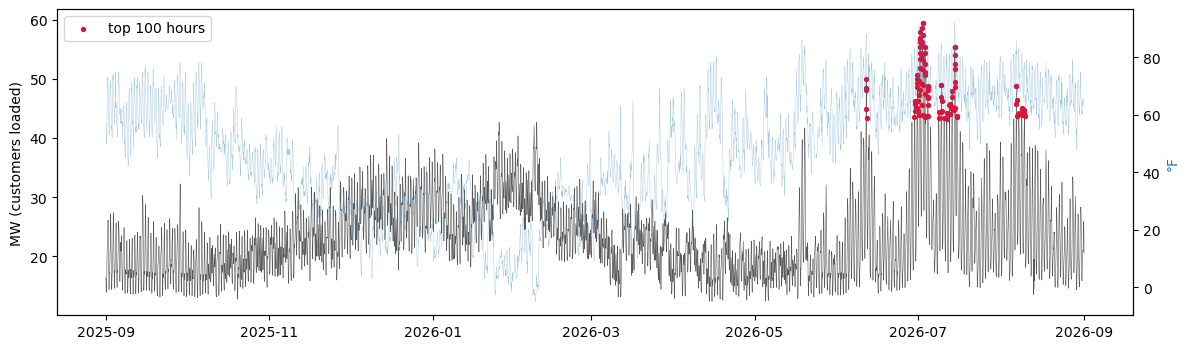

Top 10 system hours:


,ts,system_kw
7313,2026-07-02 17:00:00,59437.951759
7314,2026-07-02 18:00:00,59406.584465
7312,2026-07-02 16:00:00,58647.027638
7289,2026-07-01 17:00:00,57897.048839
7315,2026-07-02 19:00:00,57438.678926
7290,2026-07-01 18:00:00,56969.583582
7288,2026-07-01 16:00:00,56750.821420
7311,2026-07-02 15:00:00,56237.587570
7291,2026-07-01 19:00:00,56190.544573
7316,2026-07-02 20:00:00,55540.498598


Winter peak: 42,650 kW at 2026-02-08 17:00:00
Summer peak: 59,438 kW at 2026-07-02 17:00:00


In [9]:
plots.system_load_plot(D.system, D.weather, top_n=100); plt.show()
S = D.system
top = S.nsmallest(10, "rank")[["ts", "system_kw"]]
print("Top 10 system hours:"); display(top)
print(f"Winter peak: {S.loc[S.rank_winter == 1, 'system_kw'].iloc[0]:,.0f} kW at {S.loc[S.rank_winter == 1, 'ts'].iloc[0]}")
print(f"Summer peak: {S.loc[S.rank_summer == 1, 'system_kw'].iloc[0]:,.0f} kW at {S.loc[S.rank_summer == 1, 'ts'].iloc[0]}")

## 5 · Feature table
One row per customer, with reference labels + data-quality columns + descriptive features. Every column is defined in `outputs/feature_dictionary.csv`.

In [10]:
display(D.feature_dictionary)

,feature,unit,definition
0,customer_number,id,Anonymous customer identifier (joins every table)
1,ref_ev,bool,On Avangrid's EV reference list (random ~25% s...
2,ref_hp,bool,On the heat-pump reference list (random ~25% s...
3,ref_pv,bool,On the solar PV list (complete list)
4,hours_original_missing,hours,Hours with no row in the AMI files
...,...,...,...
101,cp_heat_slope,kWh/day/°F,Extra daily kWh per °F the daily mean is below...
102,cp_heat_balance_f,°F,Heating balance point (daily mean temp where h...
103,cp_cool_slope,kWh/day/°F,Extra daily kWh per °F the daily mean is above...
104,cp_cool_balance_f,°F,Cooling balance point


In [11]:
D.table.describe().T[["mean", "min", "25%", "50%", "75%", "max"]].round(3)

,mean,min,25%,50%,75%,max
customer_number,18963.513,1.0,6421.000,22851.000,29287.000,35725.000
hours_original_missing,54.618,2.0,2.000,2.000,16.000,8676.000
hours_zero_glitch_masked,0.609,0.0,0.000,0.000,1.000,13.000
hours_spike_masked,0.000,0.0,0.000,0.000,0.000,6.000
hours_filled_linear,2.535,0.0,2.000,2.000,3.000,15.000
...,...,...,...,...,...,...
cp_heat_slope,0.338,0.0,0.000,0.132,0.375,7.901
cp_heat_balance_f,52.021,40.0,44.000,52.000,58.000,68.000
cp_cool_slope,1.250,0.0,0.431,1.106,1.809,20.538
cp_cool_balance_f,62.165,56.0,58.000,62.000,66.000,76.000


## 6 · Reference customers
Avangrid's workbook: **200 EV** customers (random ~25% of likely EV homes), **100 heat-pump** customers (random ~25%), and **all 434 solar PV** customers. For EV and HP, an unlisted customer is *unlabeled*, not negative: about 3 in 4 true EV/HP homes are not on the list.

In [12]:
display(labels.implied_prevalence(D.refs, n_customers=35725))
print("Reference customers present in the loaded data:")
print(T[["ref_ev", "ref_hp", "ref_pv"]].sum().to_string())

,technology,labeled,sample_fraction,implied_total,implied_share
0,ev,200,0.25,800,0.022393
1,hp,100,0.25,400,0.011197
2,pv,434,1.00,434,0.012148


Reference customers present in the loaded data:
ref_ev    140
ref_hp     60
ref_pv    316


Average day × hour shape of each reference group vs a random sample of other analysis-ready customers. Each customer is divided by their own mean, so shape is compared, not size.

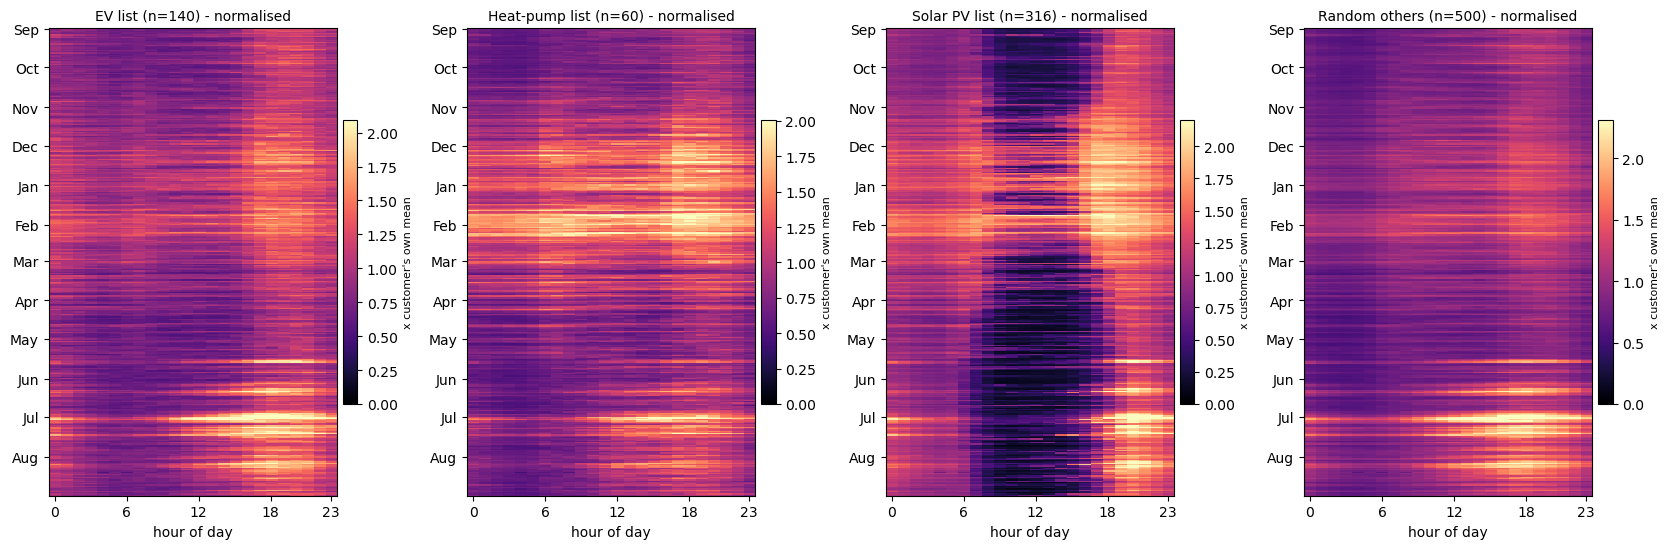

In [13]:
rng = np.random.default_rng(0)
others = T[T.analysis_ready & ~T.ref_ev & ~T.ref_hp & ~T.ref_pv].customer_number.to_numpy()
groups = {"EV list": T[T.ref_ev].customer_number.to_numpy(),
          "Heat-pump list": T[T.ref_hp].customer_number.to_numpy(),
          "Solar PV list": T[T.ref_pv].customer_number.to_numpy(),
          "Random others": rng.choice(others, 500, replace=False)}
plots.group_mean_heatmaps(D.kwh, D.customers, groups); plt.show()

Medians of a few features by group (descriptive only, not a classifier):

In [14]:
cols = ["annual_kwh", "max_kw", "p99_kw", "hours_ge7kw", "n_upramps_ge6kw", "share_night_0to6",
        "cp_heat_slope", "cp_cool_slope", "kw_temp_lt10", "cold10_to_mild_ratio",
        "zero_share_summer_10to16", "kw_sys_top50_winter", "kw_sys_top50_summer"]
g = pd.concat({"EV list": T[T.ref_ev][cols].median(), "HP list": T[T.ref_hp][cols].median(),
               "PV list": T[T.ref_pv][cols].median(), "everyone else": T[~T.ref_ev & ~T.ref_hp & ~T.ref_pv][cols].median()}, axis=1)
g.round(3)

,EV list,HP list,PV list,everyone else
annual_kwh,9910.532,9872.662,8096.899,6537.931
max_kw,7.762,6.609,6.811,5.320
p99_kw,4.644,4.091,3.993,3.132
hours_ge7kw,2.000,0.000,0.000,0.000
n_upramps_ge6kw,0.000,0.000,0.000,0.000
share_night_0to6,0.214,0.201,0.266,0.198
cp_heat_slope,0.190,0.623,0.339,0.130
cp_cool_slope,1.354,1.055,0.482,1.112
kw_temp_lt10,1.323,1.988,1.298,0.823
cold10_to_mild_ratio,1.419,1.986,2.099,1.360


### Evaluation helper (for whatever method you build)
`labels.holdout_split` keeps part of a reference list aside. `labels.pu_report` scores any ranking against it: recall in the top *k*, an **estimated precision** that corrects for the list being a 25% sample, and AUC of labeled vs everyone else.

The cell below is an **API demo only**. It ranks by `annual_kwh`, which is not a proposed method.

In [15]:
ev_train, ev_holdout = labels.holdout_split(D.refs["ev"], frac=0.3, seed=42)
demo_score = T.set_index("customer_number")["annual_kwh"]          # placeholder score
rep = labels.pu_report(demo_score, ev_holdout, label_fraction=0.25 * 0.3, ks=(100, 250, 500, 1000))
display(rep.round(3)); print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in rep.attrs.items()})

,k,hits,recall,est_precision
0,100,1,0.024,0.133
1,250,1,0.024,0.053
2,500,3,0.071,0.080
3,1000,6,0.143,0.080


{'n_labeled_in_population': 42, 'auc_labeled_vs_rest': np.float64(0.731), 'implied_total_positives': 560.0}


## 7 · Battery engine
`battery.simulate(load, request)` enforces the program unit's spec: **20.16 kWh, 7.68 kW continuous, 89.4% round-trip**, no export. The strategy (what to request each hour), the backup reserve, candidates and tariff are the team's choices (notebook `30`).

**Demo only:** one random customer, each day capped at the lowest level the battery could hold with perfect foresight.

BatterySpec(units=2, energy_kwh_per_unit=10.08, continuous_kw_per_unit=3.84, peak_kw_per_unit=5.76, round_trip_efficiency=0.894, warranty_years=15) 
one-way efficiency 0.9455; deliverable per full discharge 19.06 kWh


,customer 2169
peak_before_kw,4.48
peak_after_kw,2.33
kwh_discharged,1170.85
kwh_charged,1296.77
losses_kwh,138.12
equivalent_full_cycles,61.42
annual_kwh_before,9191.07
annual_kwh_after,9316.99
peak_reduction_kw,2.14
kw_eval_before,2.02


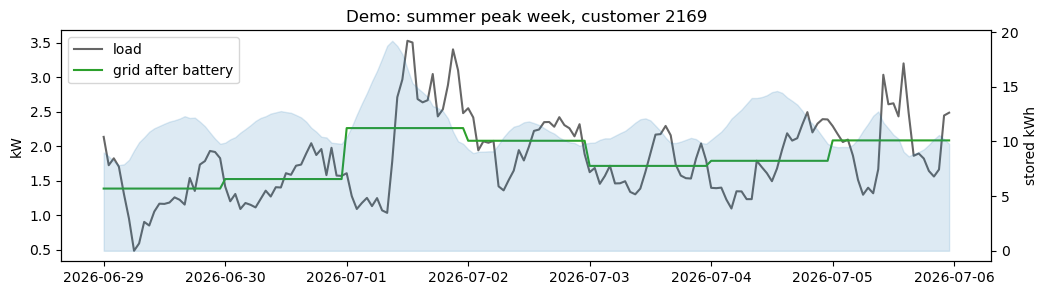

In [16]:
print(PROGRAM_BATTERY, f"\none-way efficiency {PROGRAM_BATTERY.one_way_efficiency:.4f}; "
      f"deliverable per full discharge {PROGRAM_BATTERY.energy_kwh * PROGRAM_BATTERY.one_way_efficiency:.2f} kWh")
cust = int(rng.choice(T[T.analysis_ready].customer_number))
load = D.series(cust)[None, :]
cap = battery.min_daily_cap(load)
res = battery.simulate(load, battery.cap_request(load, cap), soc_init_frac=1.0)
top100 = D.system.nsmallest(100, "rank").slot.to_numpy()
display(res.summary(eval_slots=top100).round(2).T.rename(columns={0: f"customer {cust}"}))
start = (int(D.system.loc[D.system.rank_summer == 1, "slot"].iloc[0]) // 24 - 3) * 24
wk = slice(start, start + 7 * 24); ts = D.hours.ts.iloc[wk]
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(ts, res.load_kw[0, wk], label="load", color="0.4")
ax.plot(ts, res.net_kw[0, wk], label="grid after battery", color="tab:green")
ax2 = ax.twinx(); ax2.fill_between(ts, res.soc_kwh[0, wk], alpha=0.15, color="tab:blue"); ax2.set_ylabel("stored kWh")
ax.set_ylabel("kW"); ax.legend(loc="upper left"); ax.set_title(f"Demo: summer peak week, customer {cust}"); plt.show()

## Hand-off: what's ready and what's yours

**Ready to use**
```python
D = pipeline.load_project(P)   # in any notebook
D.table                        # one row per customer: labels, quality flags, features
D.kwh                          # cleaned customer x 8760 matrix (memory-mapped, rows = D.customers)
D.series(30001)                # one customer's 8760 hourly kW
D.hours / D.weather / D.weather_daily / D.system
plots.heatmap(D.series(c)); plots.heatmap_grid(D.kwh, D.customers, ids)
labels.pu_report(scores, holdout, label_fraction)
battery.simulate(load, request)
```
Plus `outputs/seasonal_profiles.parquet` (season × day type × hour) and `outputs/daily_kwh.parquet` (365 days).

**Your decisions (notebooks 10 / 20 / 30)**
* Part 1: the evidence and rules (or model) for each technology, the confidence scores, and how you validate without full labels.
* Part 2: which segments, how they're defined, what each means for the utility.
* Part 3: which customers are candidates, dispatch strategy, sizing (1 vs 2 units), reserve, tariff, ranking and valuation.

**Data limits to state in the deck:** imports only (solar export not visible), hourly not 15-minute, one weather station, reference lists are samples (EV/HP).